<a href="https://colab.research.google.com/github/igornvidal/apollo_analytics_academy/blob/main/Bola_rolando_por_time.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

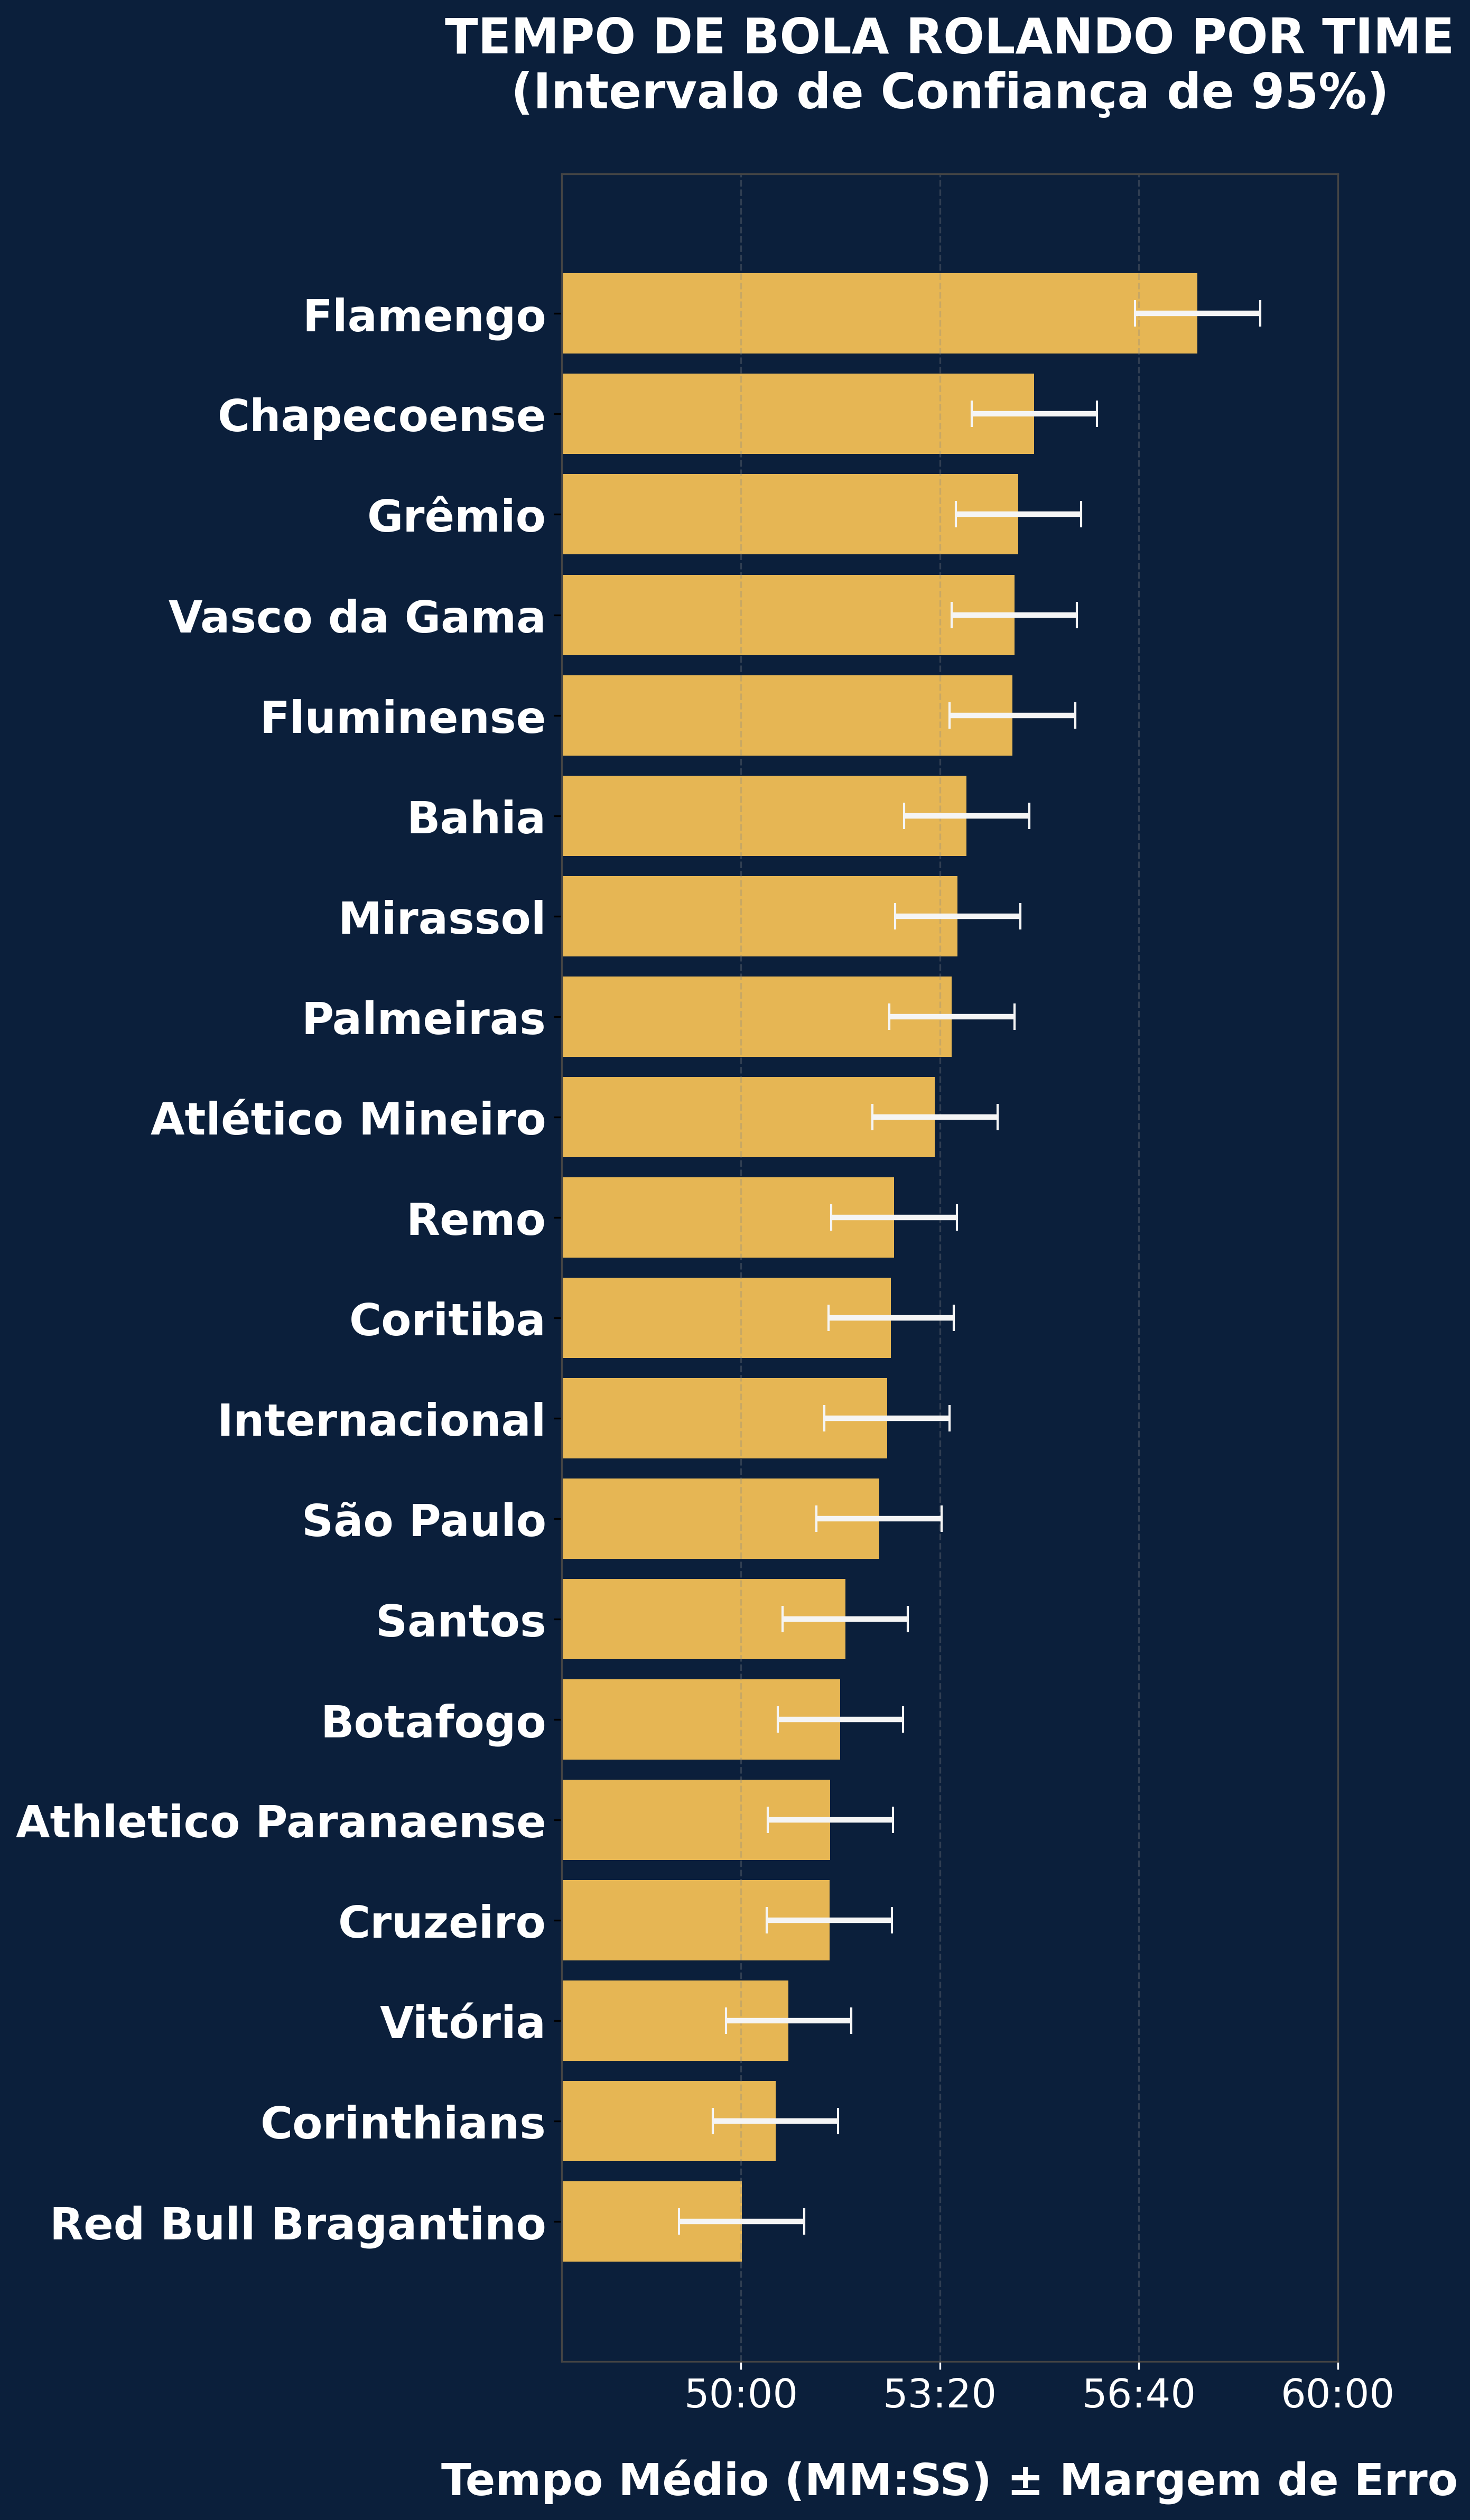

In [ ]:

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd

# Dados dos times e suas médias (extraídos do relatório da CBF Academy)
data = [
    ("Flamengo", "57:39"),
    ("Chapecoense", "54:55"),
    ("Grêmio", "54:39"),
    ("Vasco da Gama", "54:35"),
    ("Fluminense", "54:33"),
    ("Bahia", "53:47"),
    ("Mirassol", "53:38"),
    ("Palmeiras", "53:32"),
    ("Atlético Mineiro", "53:15"),
    ("Remo", "52:34"),
    ("Coritiba", "52:31"),
    ("Internacional", "52:27"),
    ("São Paulo", "52:19"),
    ("Santos", "51:45"),
    ("Botafogo", "51:40"),
    ("Athletico Paranaense", "51:30"),
    ("Cruzeiro", "51:29"),
    ("Vitória", "50:48"),
    ("Corinthians", "50:35"),
    ("Red Bull Bragantino", "50:01"),
]


# Converter mm:ss para segundos totais
def to_seconds(t_str):
  m, s = map(int, t_str.split(":"))
  return m * 60 + s


df = pd.DataFrame(data, columns=["Team", "TimeStr"])
df["Seconds"] = df["TimeStr"].apply(to_seconds)
df = df.sort_values(
    "Seconds", ascending=True
)  # Ordem ascendente para o gráfico de barras horizontal (de baixo para cima)

# Margem de erro calculada (aprox. 63 segundos / 1 min e 3 seg para cada lado)
margin_of_error = 63

# Configuração da figura para formato 9:16 (Instagram Reels)
fig, ax = plt.subplots(figsize=(9, 16), dpi=300)

# Identidade visual Apollo
bg_color = "#0b1f3b"  # Fundo escuro elegante
bar_color = "#ffc857"  # Tom dourado/bronze institucional
error_color = "#F5f5f5"  # Branco para destacar as barras de erro (whiskers)
text_color = "#FFFFFF"

fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

y_pos = np.arange(len(df))
means = df["Seconds"]
errors = [margin_of_error] * len(df)

# Gráfico de barras horizontais com barras de erro (whiskers)
bars = ax.barh(
    y_pos,
    means,
    xerr=errors,
    align="center",
    color=bar_color,
    ecolor=error_color,
    error_kw={"capsize": 6, "elinewidth": 2.5},
    alpha=0.9,
)

ax.set_yticks(y_pos)
ax.set_yticklabels(
    df["Team"], fontsize=20, color=text_color, fontweight="bold"
)
# ax.invert_yaxis()  # O líder (Flamengo) fica no topo visualmente

# Formatar o eixo X para exibir em MM:SS em vez de segundos crus


def seconds_to_mmss(x, pos):
  m = int(x // 60)
  s = int(x % 60)
  return f"{m:02d}:{s:02d}"


ax.xaxis.set_major_formatter(FuncFormatter(seconds_to_mmss))
ax.tick_params(axis="x", colors=text_color, labelsize=18)

# Zoom focado na faixa útil dos dados (de 47 min até 60 min) para máxima legibilidade mobile
ax.set_xlim(47 * 60, 60 * 60)

# Títulos e legendas otimizados para leitura rápida em vídeo
plt.title(
    "TEMPO DE BOLA ROLANDO POR TIME\n(Intervalo de Confiança de 95%)",
    fontsize=22,
    color=text_color,
    fontweight="bold",
    pad=30,
    loc="center",
)

plt.xlabel(
    "Tempo Médio (MM:SS) ± Margem de Erro",
    fontsize=20,
    color=text_color,
    labelpad=20,
    fontweight="bold",
)

# Estilização das bordas e grid
for spine in ax.spines.values():
  spine.set_color("#444444")

ax.grid(axis="x", linestyle="--", alpha=0.3, color="#888888")

plt.tight_layout()
plt.savefig(
    "reels_intervalo_confianca_zoom.png",
    facecolor=fig.get_facecolor(),
    edgecolor="none",
)

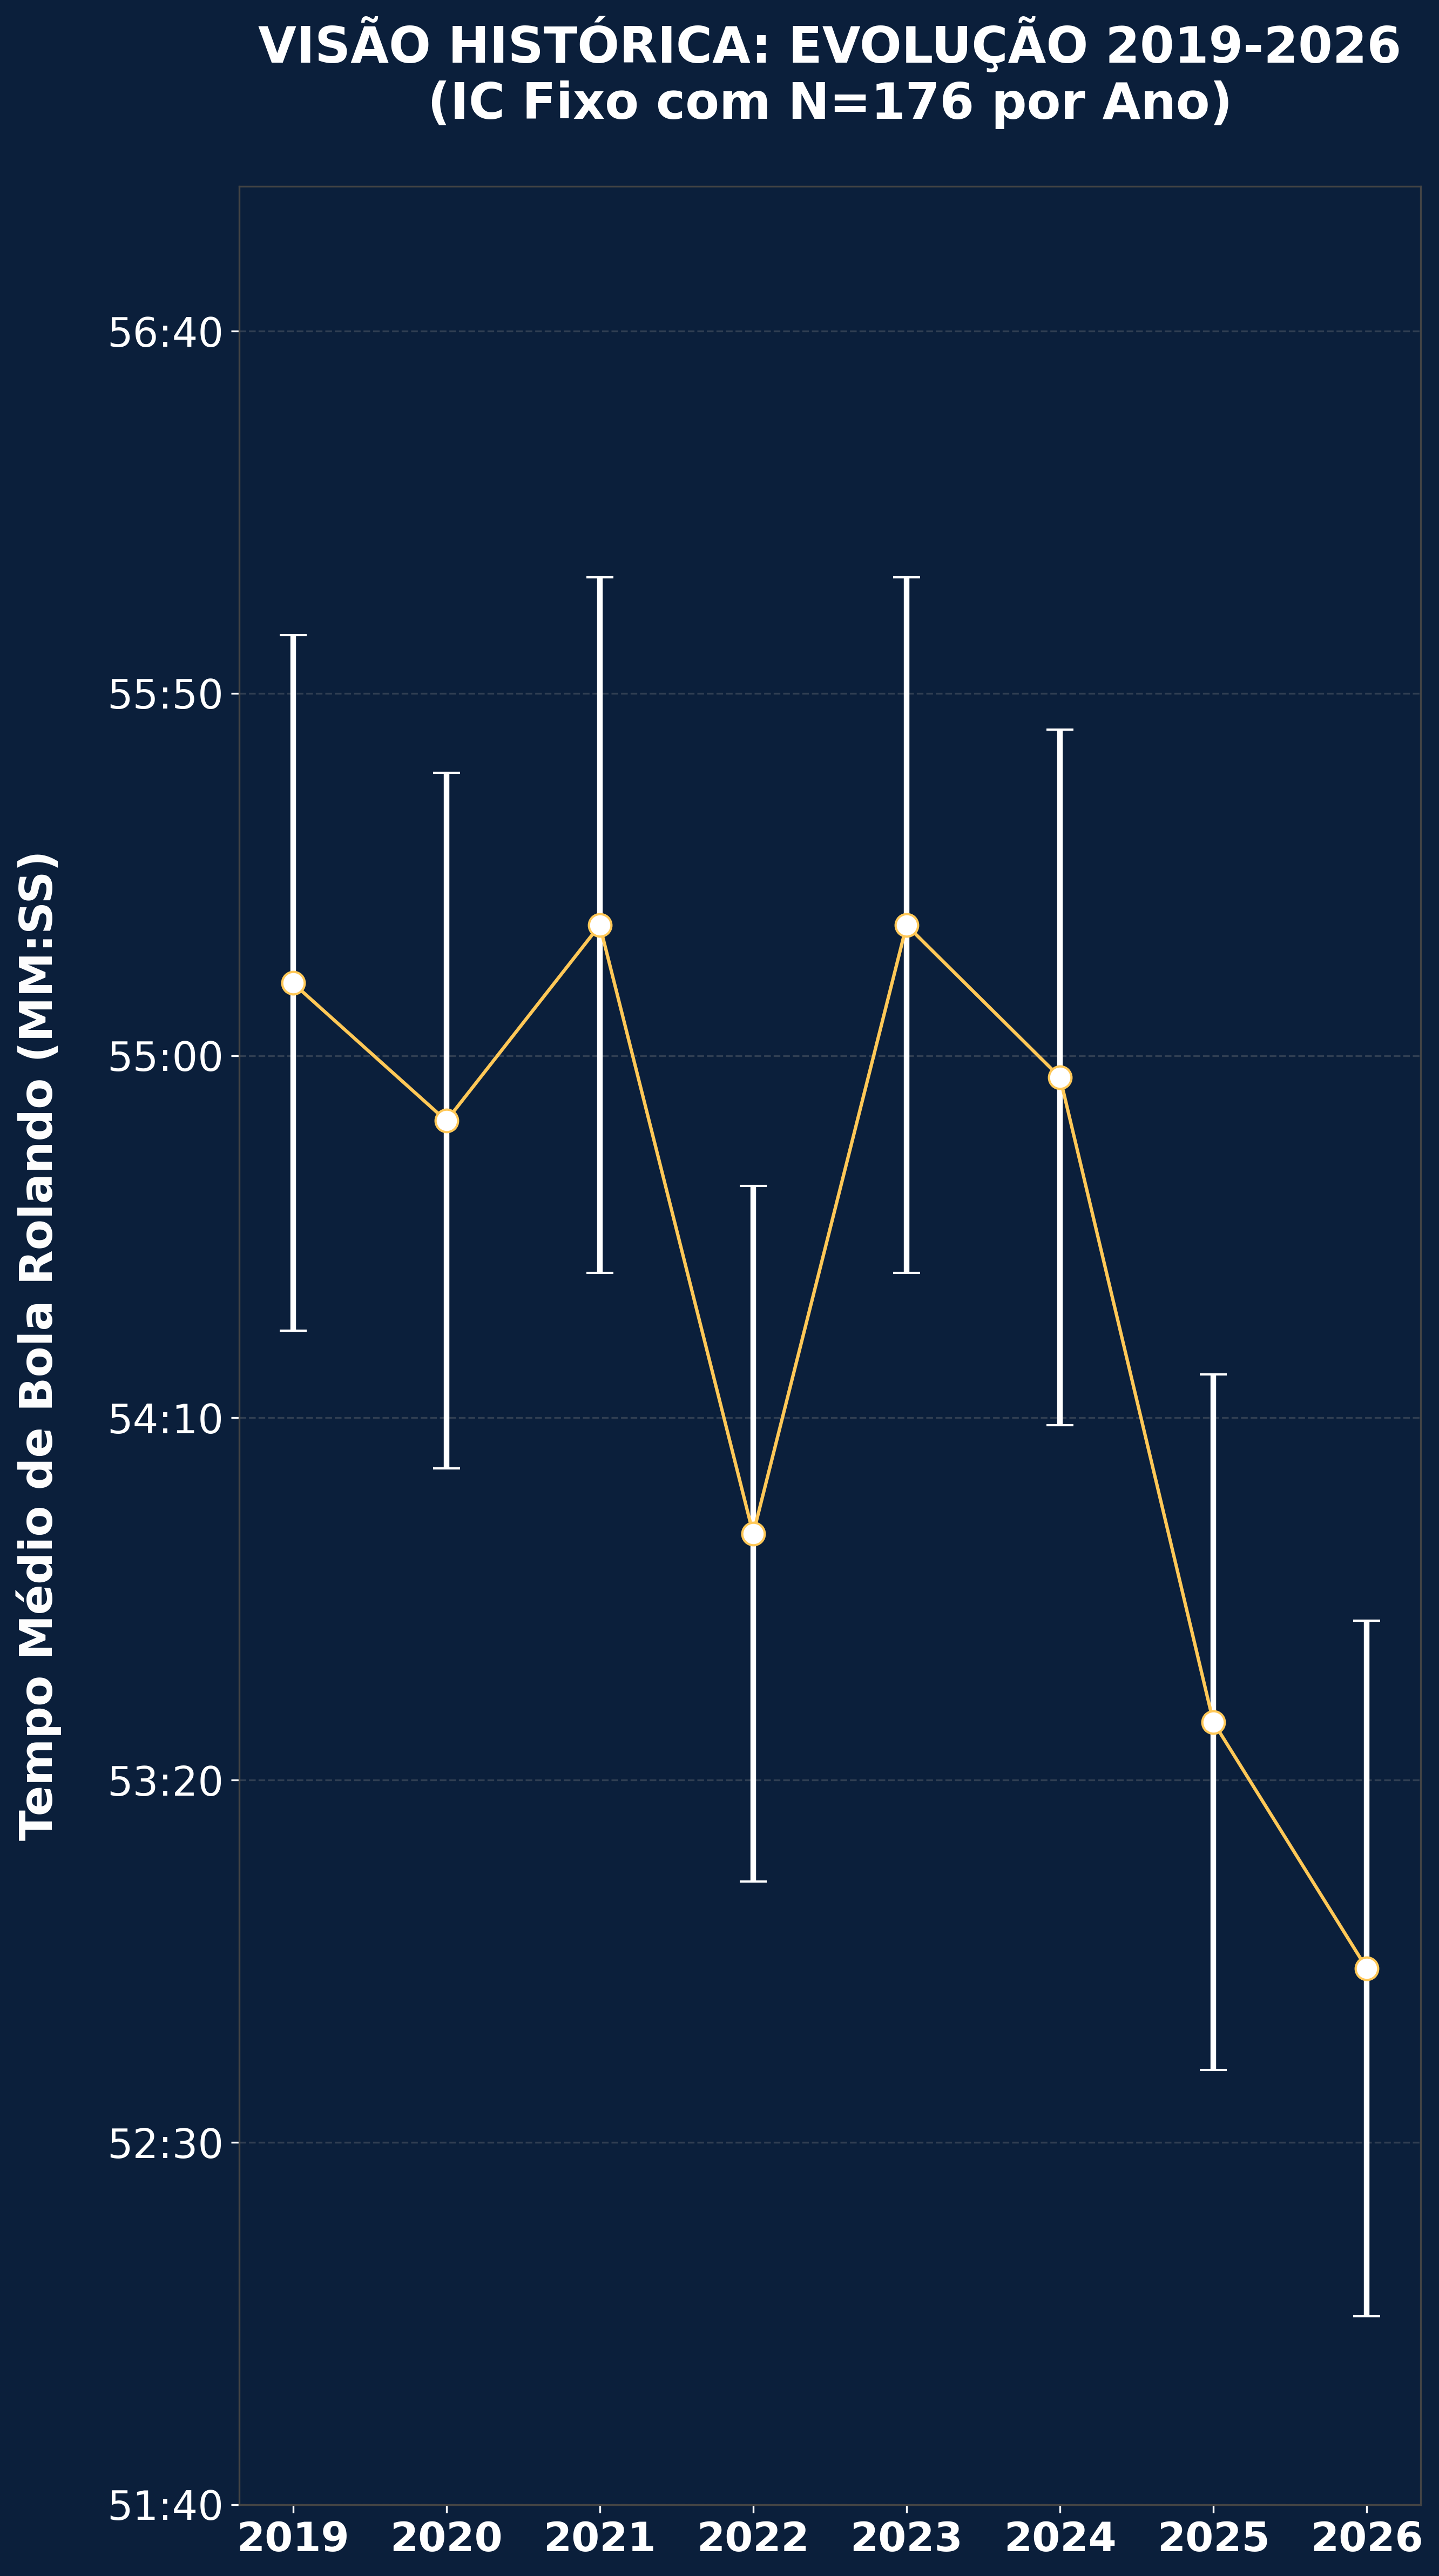

In [ ]:

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd

# Dados históricos (Ano, Tempo em Segundos, String)
history_data = [
    ("2019", 3310, "55:10"),
    ("2020", 3291, "54:51"),
    ("2021", 3318, "55:18"),
    ("2022", 3234, "53:54"),
    ("2023", 3318, "55:18"),
    ("2024", 3297, "54:57"),
    ("2025", 3208, "53:28"),
    ("2026", 3174, "52:54"),
]

df_hist = pd.DataFrame(history_data, columns=["Year", "Seconds", "Label"])

# Margem de erro fixa baseada em N=176 e desvio padrão de 324 seg (~47.8 segundos)
margin_of_error = 48

# Configuração da figura (Formato 9:16 para Reels)
fig, ax = plt.subplots(figsize=(9, 16), dpi=300)

bg_color = "#0b1f3b"
line_color = "#ffc857"
text_color = "#FFFFFF"

fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

x = np.arange(len(df_hist))
y = df_hist["Seconds"]
errors = [margin_of_error] * len(df_hist)

# Linha temporal com barras de erro padronizadas
ax.errorbar(
    x,
    y,
    yerr=errors,
    fmt="-o",
    color=line_color,
    ecolor="#FFFFFF",
    elinewidth=2.5,
    capsize=6,
    markersize=10,
    markerfacecolor="#FFFFFF",
    markeredgecolor=line_color,
)

ax.set_xticks(x)
ax.set_xticklabels(
    df_hist["Year"], fontsize=20, color=text_color, fontweight="bold"
)


# Formatar eixo Y em MM:SS
def seconds_to_mmss(val, pos):
  m = int(val // 60)
  s = int(val % 60)
  return f"{m:02d}:{s:02d}"


ax.yaxis.set_major_formatter(FuncFormatter(seconds_to_mmss))
ax.tick_params(axis="y", colors=text_color, labelsize=18)
ax.tick_params(axis="x", colors=text_color, labelsize=18)

# Zoom focado na faixa de variação histórica
ax.set_ylim(3100, 3420)

# Títulos e formatação
plt.title(
    "VISÃO HISTÓRICA: EVOLUÇÃO 2019-2026\n(IC Fixo com N=176 por Ano)",
    fontsize=22,
    color=text_color,
    fontweight="bold",
    pad=30,
    loc="center",
)

plt.ylabel(
    "Tempo Médio de Bola Rolando (MM:SS)",
    fontsize=20,
    color=text_color,
    labelpad=20,
    fontweight="bold",
)

# Estilização de fundo e grades
for spine in ax.spines.values():
  spine.set_color("#444444")

ax.grid(axis="y", linestyle="--", alpha=0.3, color="#888888")

plt.tight_layout()
plt.savefig(
    "reels_evolucao_historica_ic_fixo.png",
    facecolor=fig.get_facecolor(),
    edgecolor="none",
)